# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло. Він лежить в архіві демо-матеріалів лекції 3 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:
1. Проста імпутація ігнорує зв’язки між ознаками. kNN-імпутація враховує решту ознак того самого рядка: для кожної колонки з пропусками тренується окремий KNeighborsRegressor на повністю заповнених рядках train. Таким чином підставлене значення базується на схожих спостереженнях, а не на одній глобальній статистиці. Моделі навчають тільки на train і застосовують до val/test, щоб уникнути data leakage.
2. Під час тренування оптимізатор мінімізує саме ту функцію втрат, яку було задано (MSELoss). Тому в циклі навчання зручно і правильно дивитися тільки на MSE — це безпосередній сигнал оптимізації. Після тренування нам потрібна повна картина якості моделі: RMSE (в одиницях таргету), MAE (менш чутлива до викидів), R² (частка поясненої дисперсії). Тому на test рахуємо всі чотири метрики.
3. Після стандартизації абсолютні значення ваг показують відносну важливість ознак. Найвпливовішою виявилася MedInc (дохід). Інженерія ознак виправдала себе: diag_coord і bedperroom мають помітні ваги, тобто нові ознаки несуть корисний сигнал і лінійна модель їх використовує.
4. Baseline потрібен, щоб зрозуміти, чи взагалі модель щось навчилася, чи просто «вгадує».
У демо baseline — це завжди прогнозувати середнє значення таргету по train (y_train.mean()). Якщо модель не б’є цей примітивний прогноз — вона марна.
Для нейронної мережі baseline — це вже лінійна регресія. Якщо NN не покращує результати лінійної моделі, сенсу в ній на цих даних немає.


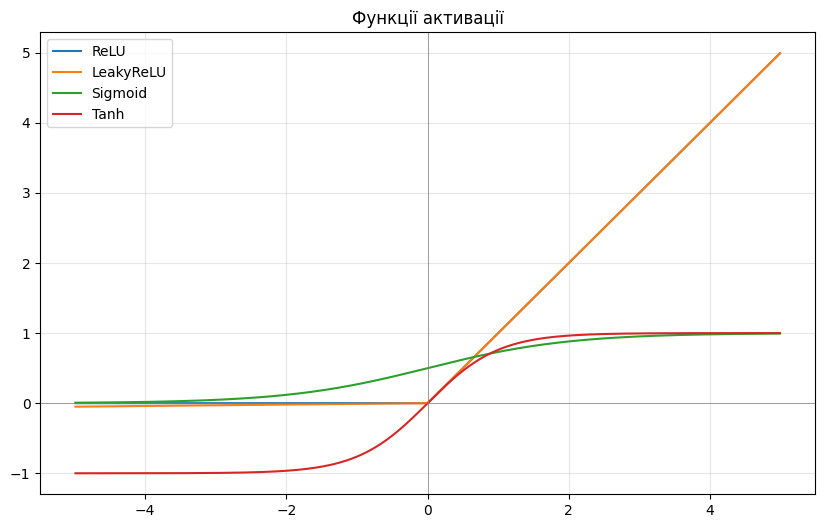

In [18]:
#5 task
import torch
import matplotlib.pyplot as plt
x = torch.sort(torch.rand(1000) * 10 - 5).values

activations = {
    "ReLU": torch.nn.ReLU(),
    "LeakyReLU": torch.nn.LeakyReLU(0.01),
    "Sigmoid": torch.nn.Sigmoid(),
    "Tanh": torch.nn.Tanh(),
}

plt.figure(figsize=(10, 6))
for name, act in activations.items():
    y = act(x)
    plt.plot(x.numpy(), y.detach().numpy(), label=name)

plt.axhline(0, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)
plt.legend()
plt.title("Функції активації")
plt.grid(alpha=0.3)
plt.show()

6. Архітектура: n_features → 64 → 32 → 1.

1-й шар: n_features * 64 + 64 (ваги + bias)
2-й шар: 64 * 32 + 32
3-й шар: 32 * 1 + 1

Сума цих чисел і дає загальну кількість параметрів (у демо це ~330 разів більше, ніж у лінійної моделі).

7. Ні, не обов’язково оптимально. У демо 200 епох. На кривій навчання видно, що train і val ще повільно спадають наприкінці — тобто моделі, ймовірно, є куди рости. Але й ризик overfitting зростає з кількістю епох. Оптимальну кількість краще визначати за поведінкою val-loss (рання зупинка, коли val перестає покращуватися).

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [19]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Грицай Іван Вікторович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#7): Bike Sharing Demand


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

Використовуємо: cpu
Seed: 42
DatasetDict({
    train: Dataset({
        features: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt'],
        num_rows: 17379
    })
})

Розмір таблиці: (17379, 17)
Колонки: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

train: (10427, 17)
val:   (3476, 17)
test:  (3476, 17)

--- head ---
       instant      dteday  season  yr  mnth  hr  holiday  weekday  \
3219      3220  2011-05-19       2   0     5   1        0        4   
14197    14198  2012-08-19       3   1     8  18        0        0   
6282      6283  2011-09-24       4   0     9   8        0        6   
16019    16020  2012-11-05       4   1    11   4        0        1   
7449      7450  2011-11-12       4   0    11   0        0        6   

       working

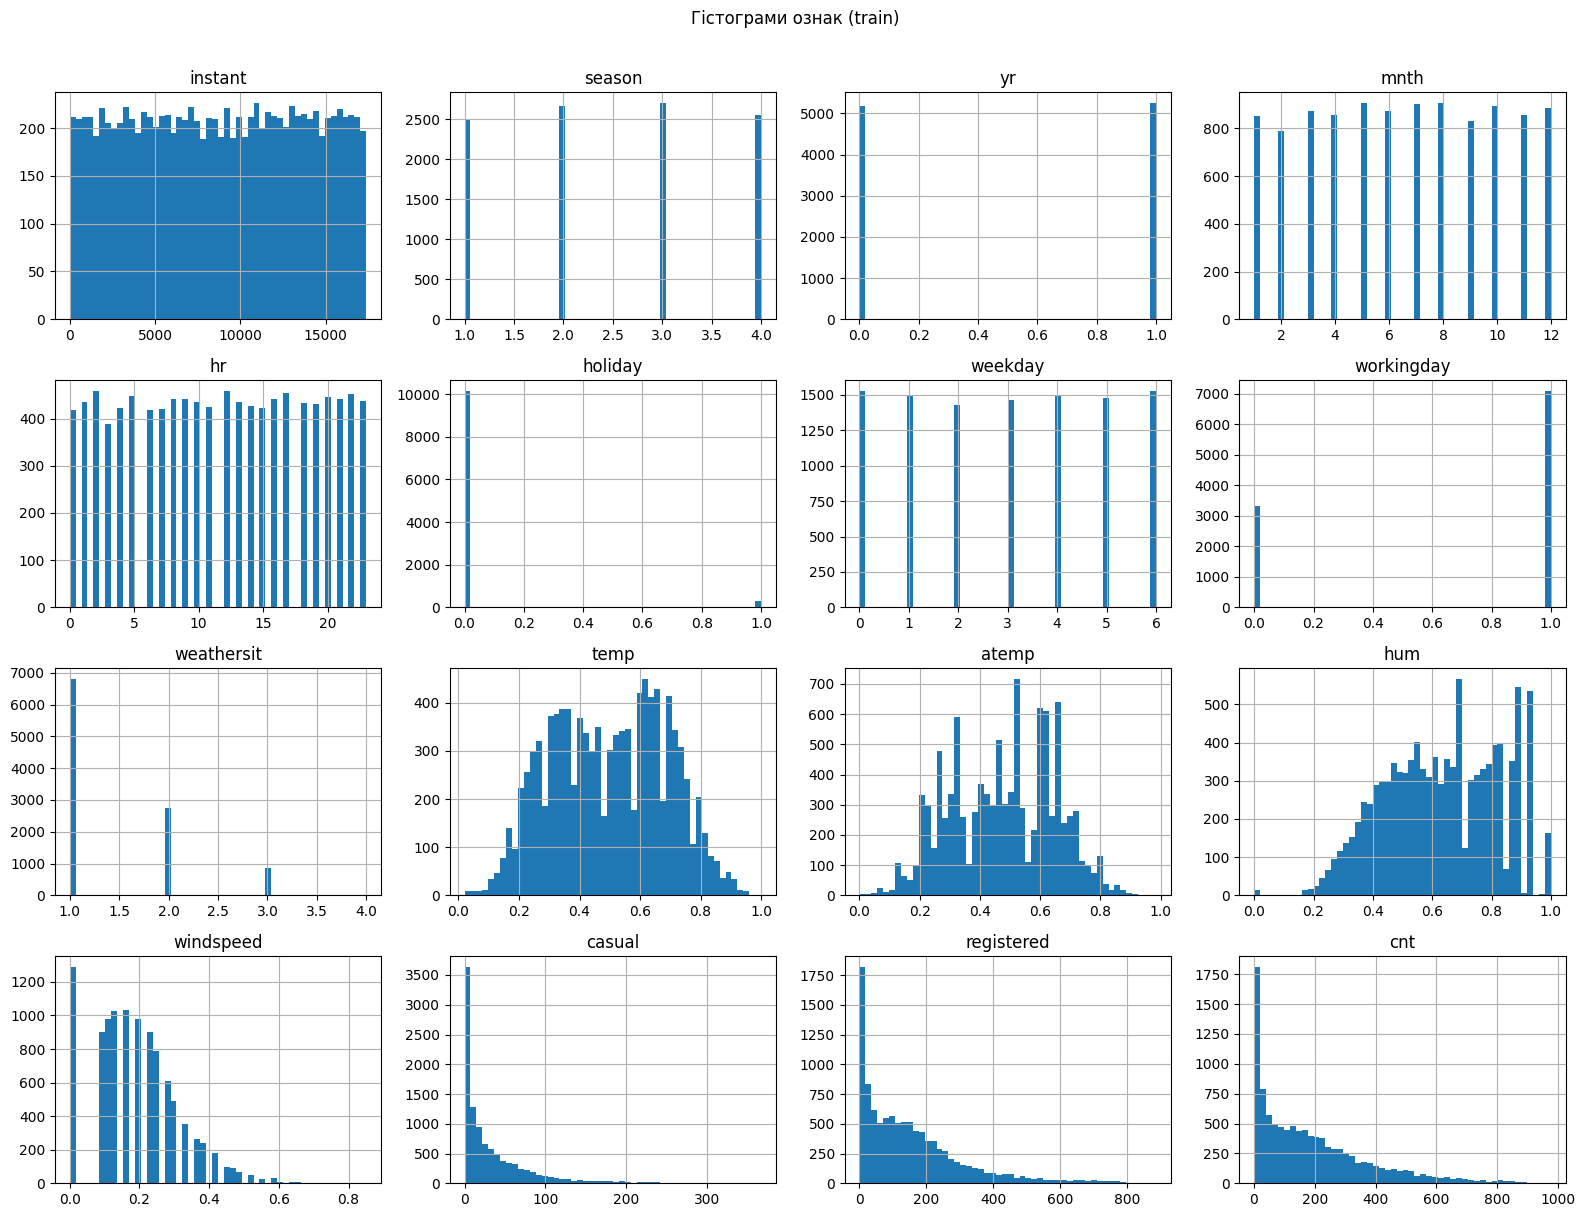

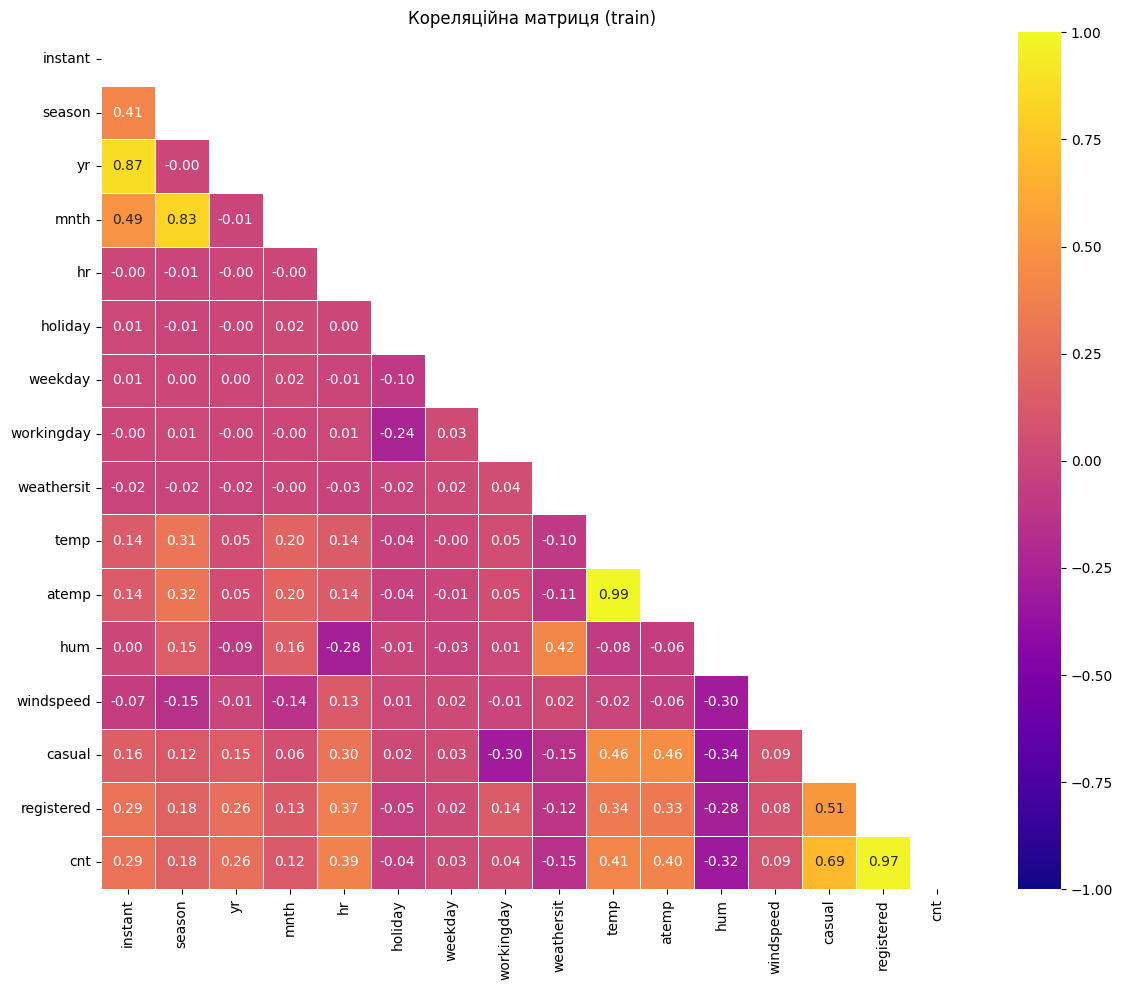


Діапазон cnt (train): 1 — 976
Квантилі cnt:
0.01      2.00
0.05      5.00
0.50    145.00
0.95    566.00
0.99    785.74
Name: cnt, dtype: float64

Колонки після feature engineering:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']
Форма train: (10427, 12)
Ознаки: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']
Форма X_train: (10427, 11)
epoch    0  train=70016.1016  val=65529.9258
epoch   20  train=40902.4570  val=38321.0195
epoch   40  train=29197.4727  val=27387.4297
epoch   60  train=24304.1328  val=22837.0449
epoch   80  train=22203.3105  val=20902.0254
epoch  100  train=21285.1855  val=20070.1816
epoch  120  train=20878.9180  val=19711.8242
epoch  140  train=20697.3477  val=19558.4219
epoch  160  train=20615.3750  val=19493.8574
epoch  180  train=20577.8652  val=19467.5977
epoch  199  train=20560.9551  val=19457.9180


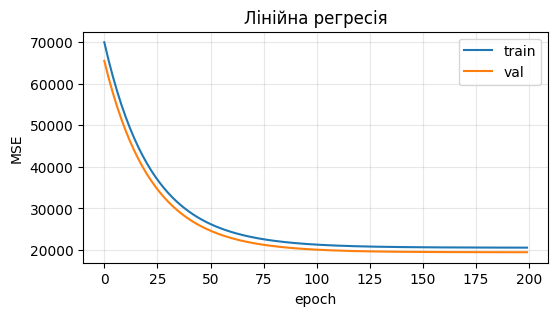

baseline_mean         MSE=31462.3599  RMSE=177.3763  MAE=139.8064  R2=-0.0012
linear                MSE=19650.6504  RMSE=140.1808  MAE=105.4617  R2=0.3747
   feature     weight
      temp  54.099575
        hr  52.183170
        yr  41.133427
       hum -37.497269
    season  19.257917
   holiday  -4.434941
      mnth   4.111922
 windspeed   3.849229
weathersit  -3.775324
   weekday   3.079501
workingday   2.713618
Sequential(
  (0): Linear(in_features=11, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Параметрів nn_v1: 2881
[nn_v1_2layers] epoch    0  train=70218.1250  val=67767.8438
[nn_v1_2layers] epoch   20  train=57494.2930  val=53666.2266
[nn_v1_2layers] epoch   40  train=22801.6855  val=22498.7578
[nn_v1_2layers] epoch   60  train=21056.9492  val=19857.5566
[nn_v1_2layers] epoch   80  train=20339.9023  val=19100.4043
[nn_v1_2layers] epoch  100  train=2009

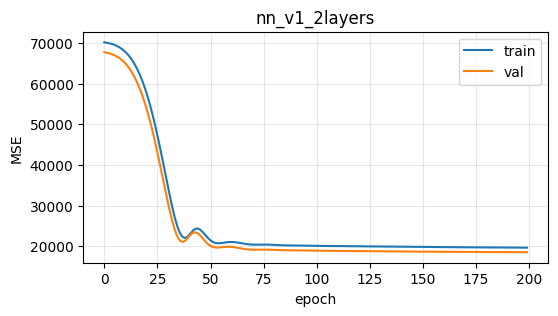

Sequential(
  (0): Linear(in_features=11, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): ReLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Параметрів nn_v2: 11905
[nn_v2_deeper] epoch    0  train=70175.6406  val=67702.9453
[nn_v2_deeper] epoch   20  train=29669.6094  val=29619.9453
[nn_v2_deeper] epoch   40  train=21373.7754  val=20239.6992
[nn_v2_deeper] epoch   60  train=20275.5977  val=19072.6855
[nn_v2_deeper] epoch   80  train=19945.1641  val=18809.1270
[nn_v2_deeper] epoch  100  train=19792.6738  val=18670.3750
[nn_v2_deeper] epoch  120  train=19692.5957  val=18594.9395
[nn_v2_deeper] epoch  140  train=19609.5059  val=18524.2559
[nn_v2_deeper] epoch  160  train=19496.8535  val=18426.2891
[nn_v2_deeper] epoch  180  train=19237.1758  val=18179.3184
[nn_v2_deeper] epoch  199  train=18720.3379  val=17697.0762
nn_v2_deeper          MSE=1

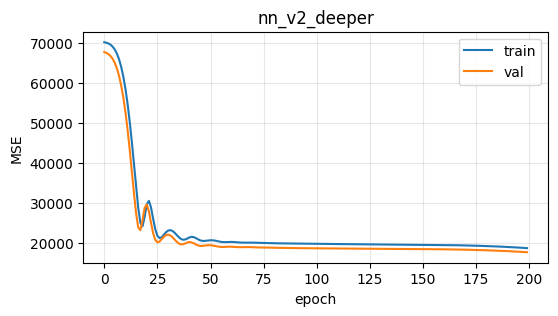

[nn_v2_lr_0.001] epoch    0  train=70131.1094  val=67776.9688
[nn_v2_lr_0.001] epoch   20  train=69609.2500  val=67211.8438
[nn_v2_lr_0.001] epoch   40  train=66915.1562  val=64344.0938
[nn_v2_lr_0.001] epoch   60  train=57760.1641  val=54846.0039
[nn_v2_lr_0.001] epoch   80  train=38540.2344  val=35711.1484
[nn_v2_lr_0.001] epoch  100  train=23783.7051  val=22540.5762
[nn_v2_lr_0.001] epoch  120  train=22082.7168  val=20986.9023
[nn_v2_lr_0.001] epoch  140  train=21331.4121  val=20235.0312
[nn_v2_lr_0.001] epoch  160  train=20995.5527  val=19880.4023
[nn_v2_lr_0.001] epoch  180  train=20799.5625  val=19660.7129
[nn_v2_lr_0.001] epoch  199  train=20665.2188  val=19511.3711
nn_v2_lr_0.001        MSE=19879.8203  RMSE=140.9958  MAE=105.8908  R2=0.3674


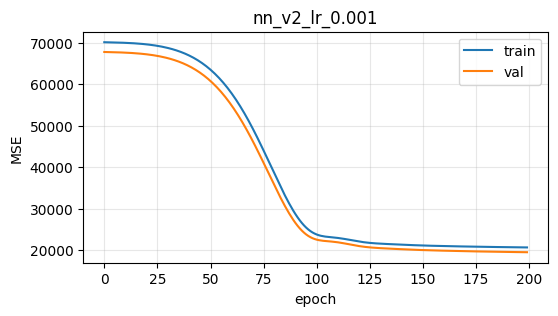

[nn_v2_sgd] epoch    0  train=70112.3984  val=67747.4766
[nn_v2_sgd] epoch   20  train=67748.3438  val=64460.7734
[nn_v2_sgd] epoch   40  train=24161.8145  val=22770.5117
[nn_v2_sgd] epoch   60  train=23930.2070  val=22298.0293
[nn_v2_sgd] epoch   80  train=23397.2109  val=21700.4531
[nn_v2_sgd] epoch  100  train=21323.2715  val=20758.0664
[nn_v2_sgd] epoch  120  train=18859.1309  val=19840.3535
[nn_v2_sgd] epoch  140  train=18094.3789  val=28357.8574
[nn_v2_sgd] epoch  160  train=15207.5977  val=19936.3633
[nn_v2_sgd] epoch  180  train=13682.9941  val=16257.0527
[nn_v2_sgd] epoch  199  train=19783.5254  val=13402.2598
nn_v2_sgd             MSE=13601.3203  RMSE=116.6247  MAE=84.9172  R2=0.5672


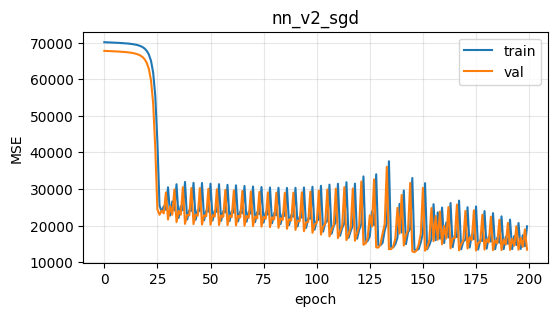

[nn_v2_epochs_400] epoch    0  train=70267.1484  val=67826.8281
[nn_v2_epochs_400] epoch   20  train=24630.6270  val=25672.4004
[nn_v2_epochs_400] epoch   40  train=20804.2676  val=19696.6172
[nn_v2_epochs_400] epoch   60  train=20231.3926  val=19058.9180
[nn_v2_epochs_400] epoch   80  train=19997.9629  val=18912.4062
[nn_v2_epochs_400] epoch  100  train=19830.8379  val=18727.2695
[nn_v2_epochs_400] epoch  120  train=19725.8164  val=18649.4043
[nn_v2_epochs_400] epoch  140  train=19647.3496  val=18583.5352
[nn_v2_epochs_400] epoch  160  train=19584.0684  val=18530.0020
[nn_v2_epochs_400] epoch  180  train=19528.8047  val=18483.4570
[nn_v2_epochs_400] epoch  200  train=19475.9746  val=18435.0820
[nn_v2_epochs_400] epoch  220  train=19427.6035  val=18392.5625
[nn_v2_epochs_400] epoch  240  train=19384.5020  val=18356.0820
[nn_v2_epochs_400] epoch  260  train=19345.1055  val=18320.7559
[nn_v2_epochs_400] epoch  280  train=19307.5273  val=18285.6270
[nn_v2_epochs_400] epoch  300  train=192

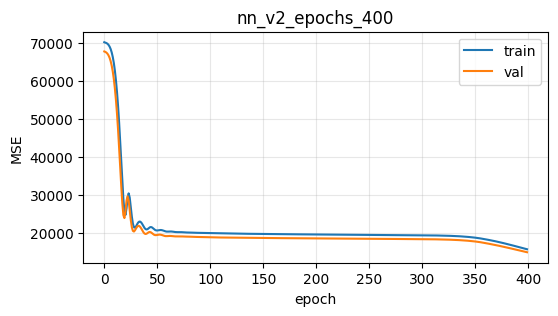

Sequential(
  (0): Linear(in_features=11, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): ReLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)

In [20]:
import sys
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from torch.utils.tensorboard import SummaryWriter
from datasets import load_dataset

SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)
print("Seed:", SEED)

# ============================================================
# 2.1 Підготовка даних
# ============================================================

# 2.1.1
from datasets import load_dataset

ds = load_dataset("t22000t/bike-sharing-tabular")
print(ds)

df = ds["train"].to_pandas()
print("\nРозмір таблиці:", df.shape)
print("Колонки:", df.columns.tolist())
df.head()

# 2.1.2
from sklearn.model_selection import train_test_split

TARGET = "cnt"

train_df, temp_df = train_test_split(df, test_size=0.4, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED)

print(f"\ntrain: {train_df.shape}")
print(f"val:   {val_df.shape}")
print(f"test:  {test_df.shape}")

# 2.1.3
print("\n--- head ---")
print(train_df.head())

print("\n--- info ---")
train_df.info()

print("\n--- describe ---")
print(train_df.describe())

# 2.1.4
print("\nПропуски по колонках:")
print(train_df.isnull().sum())
print("Всього пропусків:", train_df.isnull().sum().sum())

# 2.1.5
train_df.hist(bins=50, figsize=(16, 12))
plt.suptitle("Гістограми ознак (train)", y=1.01)
plt.tight_layout()
plt.show()

import seaborn as sns

def corr_mat(dataframe):
    corr = dataframe.corr(numeric_only=True).round(2)
    plt.figure(figsize=(12, 10))
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, vmin=-1, vmax=1, center=0,
                cmap="plasma", annot=True, lw=0.5, fmt=".2f")
    plt.title("Кореляційна матриця (train)")
    plt.tight_layout()
    plt.show()

corr_mat(train_df)

# 2.1.6
print("\nДіапазон cnt (train):", train_df["cnt"].min(), "—", train_df["cnt"].max())
print("Квантилі cnt:")
print(train_df["cnt"].quantile([0.01, 0.05, 0.5, 0.95, 0.99]))

# 2.1.7
cols_to_drop = ["instant", "dteday", "casual", "registered", "atemp"]

for d in (train_df, val_df, test_df):
    d.drop(columns=cols_to_drop, inplace=True, errors="ignore")

print("\nКолонки після feature engineering:")
print(train_df.columns.tolist())
print("Форма train:", train_df.shape)

# ============================================================
# 2.2 Baseline: множинна лінійна регресія
# ============================================================

# 2.2.1 стандартизація
from sklearn.preprocessing import StandardScaler

feature_cols = [c for c in train_df.columns if c != TARGET]

scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[feature_cols])
X_val   = scaler.transform(val_df[feature_cols])
X_test  = scaler.transform(test_df[feature_cols])

y_train = train_df[TARGET].values
y_val   = val_df[TARGET].values
y_test  = test_df[TARGET].values

print("Ознаки:", feature_cols)
print("Форма X_train:", X_train.shape)

# 2.2.2 тензори
def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32).to(device),
        torch.tensor(y, dtype=torch.float32).unsqueeze(1).to(device),
    )

x_train_t, y_train_t = to_tensor(X_train, y_train)
x_val_t,   y_val_t   = to_tensor(X_val, y_val)
x_test_t,  y_test_t  = to_tensor(X_test, y_test)

# 2.2.3 тренування nn.Linear + TensorBoard
os.makedirs("models", exist_ok=True)
os.makedirs("runs", exist_ok=True)
RUNS_DIR = "runs"

n_features = X_train.shape[1]
N_EPOCHS_LIN = 200

linear_model = torch.nn.Linear(n_features, 1).to(device)
optimizer = torch.optim.SGD(linear_model.parameters(), lr=0.01)  # було 0.1 → стало 0.01
loss_fn = torch.nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "linear"))

train_losses, val_losses = [], []

for epoch in range(N_EPOCHS_LIN):
    linear_model.train()
    optimizer.zero_grad()
    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    linear_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(linear_model(x_val_t), y_val_t).item()
    val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 20 == 0 or epoch == N_EPOCHS_LIN - 1:
        print(f"epoch {epoch:4d}  train={loss.item():.4f}  val={val_loss:.4f}")

writer.close()
torch.save(linear_model.state_dict(), "models/linear.pt")

# 2.2.4 крива навчання
plt.figure(figsize=(6, 3))
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Лінійна регресія")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# 2.2.5 метрики на test
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def report(y_true, y_pred, name):
    mse  = mean_squared_error(y_true, y_pred)
    rmse = mse ** 0.5
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f"{name:20s}  MSE={mse:.4f}  RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.4f}")
    return {"model": name, "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

linear_model.eval()
with torch.no_grad():
    y_test_pred_lin = linear_model(x_test_t).cpu().numpy().flatten()

baseline_pred = np.full_like(y_test, y_train.mean())
results = []
results.append(report(y_test, baseline_pred, "baseline_mean"))
results.append(report(y_test, y_test_pred_lin, "linear"))

# 2.2.6 інтерпретація ваг
weights = linear_model.weight.detach().cpu().numpy().flatten()
weight_df = pd.DataFrame({"feature": feature_cols, "weight": weights})
weight_df["abs_weight"] = weight_df["weight"].abs()
weight_df = weight_df.sort_values("abs_weight", ascending=False).drop(columns="abs_weight")
print(weight_df.to_string(index=False))

# ============================================================
# 2.3 Нейромережа: 2 архітектури
# ============================================================

def train_model(model, name, n_epochs, lr, optim_name="adam"):
    model = model.to(device)
    if optim_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    loss_fn = torch.nn.MSELoss()
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, name))

    tr_losses, va_losses = [], []
    for epoch in range(n_epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(x_train_t)
        loss = loss_fn(pred, y_train_t)
        loss.backward()
        optimizer.step()
        tr_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            va = loss_fn(model(x_val_t), y_val_t).item()
        va_losses.append(va)

        writer.add_scalar("Loss/train", loss.item(), epoch)
        writer.add_scalar("Loss/val", va, epoch)

        if epoch % 20 == 0 or epoch == n_epochs - 1:
            print(f"[{name}] epoch {epoch:4d}  train={loss.item():.4f}  val={va:.4f}")

    writer.close()
    torch.save(model.state_dict(), f"models/{name}.pt")

    model.eval()
    with torch.no_grad():
        y_pred = model(x_test_t).cpu().numpy().flatten()
    results.append(report(y_test, y_pred, name))

    plt.figure(figsize=(6, 3))
    plt.plot(tr_losses, label="train")
    plt.plot(va_losses, label="val")
    plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title(name)
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

    return model

# 2.3.1 архітектура 1: 2 шари (64 → 32)
nn_v1 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
)
print(nn_v1)
print("Параметрів nn_v1:", sum(p.numel() for p in nn_v1.parameters()))
train_model(nn_v1, "nn_v1_2layers", n_epochs=200, lr=0.01)

# 2.3.2 архітектура 2: глибша (128 → 64 → 32)
nn_v2 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
)
print(nn_v2)
print("Параметрів nn_v2:", sum(p.numel() for p in nn_v2.parameters()))
train_model(nn_v2, "nn_v2_deeper", n_epochs=200, lr=0.01)

# ============================================================
# 2.4 Підбір гіперпараметрів (на кращій архітектурі = nn_v2)
# ============================================================

# 2.4.1 інший lr
nn_v2_lr = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
)
train_model(nn_v2_lr, "nn_v2_lr_0.001", n_epochs=200, lr=0.001)

# 2.4.2 SGD замість Adam
nn_v2_sgd = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
)
train_model(nn_v2_sgd, "nn_v2_sgd", n_epochs=200, lr=0.0001, optim_name="sgd")

# 2.4.3 більше епох
nn_v2_epochs = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
)
train_model(nn_v2_epochs, "nn_v2_epochs_400", n_epochs=400, lr=0.01)

In [21]:
import pandas as pd

pd.DataFrame(results).to_csv("results.csv", index=False)


### 2.5. Логування та порівняння моделей

Усі навчені моделі логуються в TensorBoard в окремі директорії. Для кожного варіанта зберігаються значення функції втрат на навчальній та валідаційній вибірках, що дозволяє порівнювати процес навчання моделей.

За результатами експериментів найкращий результат показала модель `nn_v2_sgd`: MSE = 13601,32, RMSE = 116,62, MAE = 84,92, R² = 0,567. Порівняно з лінійною регресією MSE зменшився приблизно на 30,8%.

Нейромережа виправдала себе на цьому датасеті, оскільки найкращі її результати перевершують результати лінійної регресії. Збільшення глибини мережі також покращило якість: модель `nn_v2_deeper` має MSE = 18040,66 проти 19650,65 у лінійної регресії.

Зменшення learning rate до 0,001 не покращило результат. Збільшення кількості епох до 400 дало кращий результат порівняно з початковою глибокою архітектурою. Найкращі тестові метрики отримано у варіанті `nn_v2_sgd`.

Водночас у цьому варіанті одночасно змінено оптимізатор і learning rate, тому неможливо однозначно визначити, який із цих двох параметрів спричинив покращення. Для точнішого порівняння потрібно змінювати по одному параметру за раз.

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [22]:
import gradio as gr

def load_model(path, architecture="v2"):
    if architecture == "linear":
        m = torch.nn.Linear(n_features, 1)
    elif architecture == "v1":
        m = torch.nn.Sequential(
            torch.nn.Linear(n_features, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 1),
        )
    else:  # v2
        m = torch.nn.Sequential(
            torch.nn.Linear(n_features, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 1),
        )
    m.load_state_dict(torch.load(path, map_location=device))
    m.to(device)
    m.eval()
    return m

models = {
    "linear": load_model("models/linear.pt", "linear"),
    "nn_v1_2layers": load_model("models/nn_v1_2layers.pt", "v1"),
    "nn_v2_deeper": load_model("models/nn_v2_deeper.pt", "v2"),
    "nn_v2_lr_0.001": load_model("models/nn_v2_lr_0.001.pt", "v2"),
    "nn_v2_sgd": load_model("models/nn_v2_sgd.pt", "v2"),
    "nn_v2_epochs_400": load_model("models/nn_v2_epochs_400.pt", "v2"),
}

def predict_all(*feature_values):
    x = scaler.transform(pd.DataFrame([feature_values], columns=feature_cols))
    x_t = torch.tensor(x, dtype=torch.float32).to(device)
    preds = {}
    for name, model in models.items():
        with torch.no_grad():
            preds[name] = model(x_t).item()
    return preds

def predict_selected(selected_model, *feature_values):
    return predict_all(*feature_values)[selected_model]

def plot_comparison(*feature_values):
    preds = predict_all(*feature_values)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(preds.keys(), preds.values(), color="#4C72B0")
    ax.set_ylabel("Прогноз cnt")
    ax.set_title("Порівняння моделей")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    return fig

def run_prediction(selected_model, *feature_values):
    return predict_selected(selected_model, *feature_values), plot_comparison(*feature_values)

with gr.Blocks(title="Bike Sharing — прогноз") as demo:
    gr.Markdown("## Прогноз кількості оренд велосипедів")
    with gr.Row():
        with gr.Column():
            sliders = []
            for col in feature_cols:
                mn = float(train_df[col].min())
                mx = float(train_df[col].max())
                mean = float(train_df[col].mean())
                sliders.append(gr.Slider(minimum=mn, maximum=mx, value=mean, label=col))
            model_choice = gr.Dropdown(
                choices=list(models.keys()),
                value="nn_v2_sgd",
                label="Модель",
            )
            submit_btn = gr.Button("Порахувати", variant="primary")
        with gr.Column():
            prediction_output = gr.Number(label="Прогноз обраної моделі")
            comparison_plot = gr.Plot(label="Порівняння всіх моделей")

    submit_btn.click(
        fn=run_prediction,
        inputs=[model_choice] + sliders,
        outputs=[prediction_output, comparison_plot],
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ec0b648fbce2d40f48.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
```